# One-Hidden-Layer Neural Network from Scratch: Report

`SimpleSLPClassifier` and `SimpleSLPRegressor` are neural networks with **one hidden layer**, written with
NumPy only. They compute

$$z_1 = X W_1 + b_1,\quad a_1 = f(z_1),\quad z_2 = a_1 W_2 + b_2,\quad \hat y = g(z_2)$$

with $f \in \{\text{relu}, \text{tanh}, \text{logistic}\}$, $g$ = sigmoid for binary classification and
$g$ = identity for regression, and are trained by mini-batch stochastic gradient descent on the
cross-entropy (classification) or the mean squared error (regression).

**Contents**
1. Setup
2. Debugging tests: gradient check, XOR, simple linear regression
3. Regression on `load_diabetes`
4. Binary classification on `load_breast_cancer`
5. Kaggle datasets: credit card default (classification), California housing (regression)
6. Early stopping
7. Effect of the batch size
8. Summary, conclusion and limitations

## 1. Setup

* Fixed seed (`SEED = 42`) everywhere, so every run gives the same numbers.
* Every dataset is split **80 % train / 20 % test** (stratified for classification).
* Features are standardized with a `StandardScaler` **fitted on the training set only**, so no
  information from the test set leaks into training.
* **Fair comparison with scikit-learn**: `sklearn_twin` builds the scikit-learn MLP with our exact
  configuration (same neurons, activation, learning rate, batch size, epochs) and plain SGD.
  Three scikit-learn defaults are switched off because our model does not have them: the L2 penalty
  (`alpha=0`), momentum (`momentum=0`) and its own stopping rule (`n_iter_no_change=max_iter`).

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer, load_diabetes
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import confusion_matrix, r2_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.preprocessing import StandardScaler

from slp_classifier import SimpleSLPClassifier
from slp_regressor import SimpleSLPRegressor

warnings.filterwarnings("ignore", category=ConvergenceWarning)  # we fix the number of epochs on purpose
SEED = 42
results = []  # (dataset, metric, model, test score), summarised in section 8


def split_and_scale(X, y, stratify=False):
    # 80/20 split, then standardize with the statistics of the TRAIN set only
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=SEED, stratify=y if stratify else None)
    scaler = StandardScaler().fit(X_train)
    return scaler.transform(X_train), scaler.transform(X_test), y_train, y_test


def sklearn_twin(model_class, config):
    # scikit-learn MLP with the same configuration as ours: plain SGD, no penalty, no early stop
    return model_class(hidden_layer_sizes=(config["hidden_layer_size"],), activation=config["activation"],
                       solver="sgd", learning_rate_init=config["learning_rate"], momentum=0.0,
                       batch_size=config["batch_size"], max_iter=config["max_iter"],
                       n_iter_no_change=config["max_iter"], alpha=0.0, random_state=SEED)


def plot_losses(curves, title, ylabel="Training loss"):
    # curves: dict label -> list of loss values (one per epoch)
    for label, values in curves.items():
        plt.plot(range(1, len(values) + 1), values, label=label)
    plt.title(title)
    plt.xlabel("Epoch")
    plt.ylabel(ylabel)
    plt.legend()
    plt.show()

**Note on the loss curves.** Ours records the loss on the whole training set after each epoch;
scikit-learn records the average of the mini-batch losses during the epoch. The values are close.

## 2. Debugging tests

### 2.1 Gradient check

A wrong gradient still makes the loss move, just badly, so backpropagation is checked against
numerical derivatives (central finite differences):

$$\frac{\partial L}{\partial w} \approx \frac{L(w + \varepsilon) - L(w - \varepsilon)}{2\varepsilon}, \qquad \varepsilon = 10^{-6}$$

A relative error around $10^{-7}$ or less means the chain rule is implemented correctly.
(The loop over the weights is only for this check; the model itself never loops over weights.)

In [2]:
def gradient_check(model, X, Y, eps=1e-6):
    # Relative error between backprop gradients and finite differences, for W1, b1, W2, b2
    analytic = model._backward_propagation(X, Y, *model._forward_propagation(X))
    errors = []
    for param, grad in zip((model.W1_, model.b1_, model.W2_, model.b2_), analytic):
        numeric = np.zeros_like(param)
        for i in np.ndindex(param.shape):
            original = param[i]
            param[i] = original + eps
            loss_plus = model._compute_loss(Y, model._forward_propagation(X)[3])
            param[i] = original - eps
            loss_minus = model._compute_loss(Y, model._forward_propagation(X)[3])
            param[i] = original
            numeric[i] = (loss_plus - loss_minus) / (2 * eps)
        errors.append(np.linalg.norm(grad - numeric) / (np.linalg.norm(grad) + np.linalg.norm(numeric)))
    return max(errors)


rng = np.random.default_rng(SEED)
X_check = rng.normal(size=(20, 4))
y_class = (X_check[:, 0] > 0).astype(int)
y_reg = X_check @ np.array([1.0, -2.0, 0.5, 0.0])

for activation in ["logistic", "tanh", "relu"]:
    # max_iter=1: we only need initialized weights, then compare gradients at that point
    clf = SimpleSLPClassifier(hidden_layer_size=5, activation=activation, max_iter=1, random_state=SEED)
    clf.fit(X_check, y_class)
    error_clf = gradient_check(clf, X_check, y_class.reshape(-1, 1).astype(float))

    reg = SimpleSLPRegressor(hidden_layer_size=5, activation=activation, max_iter=1, random_state=SEED)
    reg.fit(X_check, y_reg)
    error_reg = gradient_check(reg, X_check, ((y_reg - reg.y_mean_) / reg.y_std_).reshape(-1, 1))

    print(f"{activation:8s}  max relative error: classifier {error_clf:.1e}, regressor {error_reg:.1e}")
    assert error_clf < 1e-6 and error_reg < 1e-6

logistic  max relative error: classifier 1.4e-09, regressor 1.1e-09
tanh      max relative error: classifier 9.4e-10, regressor 1.1e-09
relu      max relative error: classifier 2.6e-10, regressor 2.2e-10


### 2.2 Classifier on XOR

No straight line separates (0,1), (1,0) from (0,0), (1,1): a linear model cannot solve XOR.
A hidden layer with a **non-linear** activation can. With 4 samples and `batch_size=32`, this is
full-batch gradient descent.

relu     predictions = [0 1 1 0] (truth = [0 1 1 0]),  P(class 1) = [0.006 0.999 0.999 0.001]
tanh     predictions = [0 1 1 0] (truth = [0 1 1 0]),  P(class 1) = [0.    0.998 0.998 0.003]
logistic predictions = [0 1 1 0] (truth = [0 1 1 0]),  P(class 1) = [0.003 0.985 0.985 0.021]


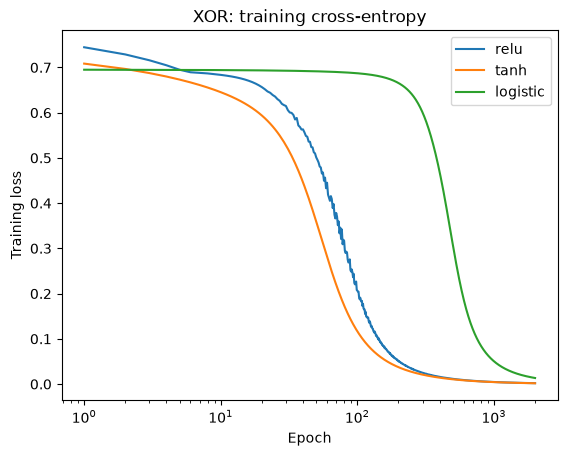

In [3]:
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y_xor = np.array([0, 1, 1, 0])

curves = {}
for activation in ["relu", "tanh", "logistic"]:
    model = SimpleSLPClassifier(hidden_layer_size=4, activation=activation, learning_rate=0.5,
                                max_iter=2000, random_state=SEED).fit(X_xor, y_xor)
    curves[activation] = model.loss_curve_
    print(f"{activation:8s} predictions = {model.predict(X_xor)} (truth = {y_xor}),  "
          f"P(class 1) = {model.predict_proba(X_xor)[:, 1].round(3)}")

plt.xscale("log")
plot_losses(curves, "XOR: training cross-entropy")

All three networks classify the 4 points correctly and the loss goes to almost 0. The logistic network
stays on a **plateau** for a few hundred epochs: the sigmoid's derivative is at most 0.25, so the error
sent back to the hidden layer is small. relu and tanh (derivative up to 1) learn faster.

### 2.3 Regressor on a simple linear regression

Data: $y = 3x + 2 + \text{noise}$. With `activation="identity"` the network is a composition of
linear maps, so it is a linear model: it should find a slope close to 3 and an intercept close to 2.

Learned slope = 3.077 (true 3), intercept = 1.979 (true 2)
Test R² = 0.9886


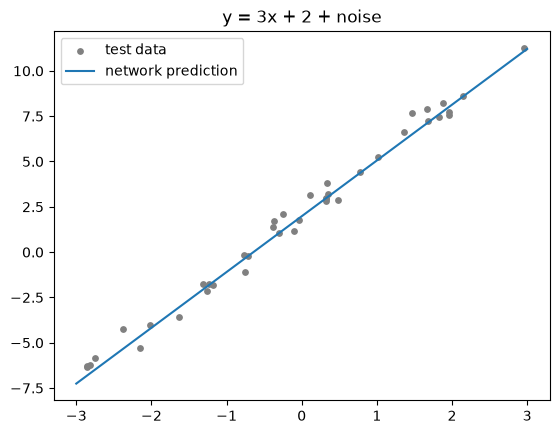

In [4]:
rng = np.random.default_rng(SEED)
x = rng.uniform(-3, 3, size=(200, 1))
y = 3 * x[:, 0] + 2 + rng.normal(0, 0.5, size=200)
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=SEED)

lin = SimpleSLPRegressor(hidden_layer_size=8, activation="identity", learning_rate=0.05,
                         max_iter=100, random_state=SEED).fit(x_train, y_train)
intercept = lin.predict([[0.0]])[0]
slope = lin.predict([[1.0]])[0] - intercept
print(f"Learned slope = {slope:.3f} (true 3), intercept = {intercept:.3f} (true 2)")
print(f"Test R² = {lin.score(x_test, y_test):.4f}")

plt.scatter(x_test, y_test, s=15, color="gray", label="test data")
line = np.linspace(-3, 3, 50).reshape(-1, 1)
plt.plot(line, lin.predict(line), label="network prediction")
plt.title("y = 3x + 2 + noise")
plt.legend()
plt.show()

## 3. Regression: diabetes dataset (`load_diabetes`)

442 patients, 10 features, target = disease progression after one year (25 to 346).
Metric: **R²** (1 = perfect, 0 = no better than predicting the mean).

Our regressor standardizes the target internally. For a fair comparison, scikit-learn is trained on the
same standardized target and its predictions are converted back. We also show what plain SGD does on the
raw target.

Configuration: 16 hidden neurons, relu, learning rate 0.01, batch size 32, 100 epochs
(small network and few epochs: only 353 training samples).

Ours     test R² = 0.503
sklearn  test R² = 0.484
sklearn on the raw target fails: Solver produced non-finite parameter weights. The input data may contain large values and need to be preprocessed.


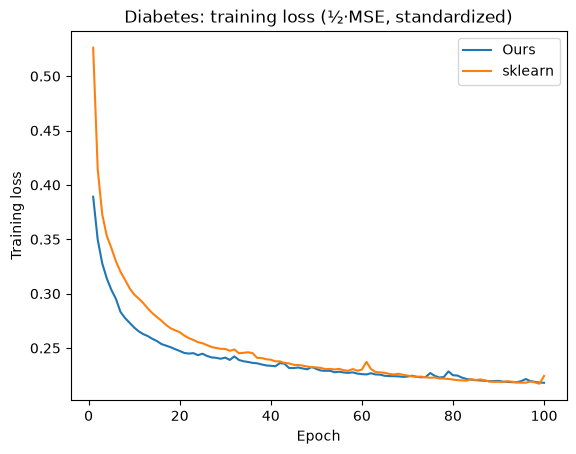

In [5]:
X, y = load_diabetes(return_X_y=True)
X_train, X_test, y_train, y_test = split_and_scale(X, y)
config = dict(hidden_layer_size=16, activation="relu", learning_rate=0.01, batch_size=32, max_iter=100)

ours = SimpleSLPRegressor(**config, random_state=SEED).fit(X_train, y_train)
y_mean, y_std = y_train.mean(), y_train.std()  # same target scaling as inside our regressor
sk = sklearn_twin(MLPRegressor, config).fit(X_train, (y_train - y_mean) / y_std)

r2_ours = ours.score(X_test, y_test)
r2_sk = r2_score(y_test, sk.predict(X_test) * y_std + y_mean)
print(f"Ours     test R² = {r2_ours:.3f}")
print(f"sklearn  test R² = {r2_sk:.3f}")

try:  # plain SGD on the raw target (values up to 346)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        sklearn_twin(MLPRegressor, config).fit(X_train, y_train)
except ValueError as error:
    print(f"sklearn on the raw target fails: {error}")

results += [("Diabetes", "R²", "Ours", r2_ours), ("Diabetes", "R²", "sklearn", r2_sk)]
plot_losses({"Ours": ours.loss_curve_, "sklearn": sk.loss_curve_}, "Diabetes: training loss (½·MSE, standardized)")

**Reading.** Both models reach a similar R² of about 0.5, typical for this small, noisy dataset, and the
loss curves almost overlap. On the **raw target**, plain SGD **diverges**: errors in the hundreds give huge
gradients, each step overshoots and the weights explode. This is why the brief recommends standardizing
continuous targets, and why our regressor does it.

## 4. Binary classification: breast cancer dataset (`load_breast_cancer`)

569 tumours, 30 features, target = malignant (0) / benign (1). Metric: **accuracy**, compared with the
majority-class baseline. The single sigmoid output gives $P(y=1)$; the prediction is 1 when it is above 0.5.

Configuration: 32 hidden neurons, relu, learning rate 0.01, batch size 32, 100 epochs.

Majority-class baseline  accuracy = 0.632
Ours                     accuracy = 0.965
sklearn                  accuracy = 0.965
predict_proba, first 3 test tumours:
 [[1.    0.   ]
 [0.    1.   ]
 [0.925 0.075]]


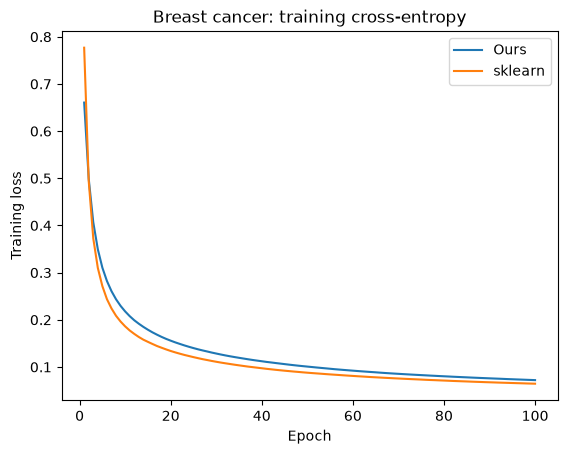

In [6]:
X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = split_and_scale(X, y, stratify=True)
config = dict(hidden_layer_size=32, activation="relu", learning_rate=0.01, batch_size=32, max_iter=100)

ours = SimpleSLPClassifier(**config, random_state=SEED).fit(X_train, y_train)
sk = sklearn_twin(MLPClassifier, config).fit(X_train, y_train)
acc_ours, acc_sk = ours.score(X_test, y_test), sk.score(X_test, y_test)
baseline = np.mean(y_test == np.bincount(y_train).argmax())  # always predict the majority class

print(f"Majority-class baseline  accuracy = {baseline:.3f}")
print(f"Ours                     accuracy = {acc_ours:.3f}")
print(f"sklearn                  accuracy = {acc_sk:.3f}")
print("predict_proba, first 3 test tumours:\n", ours.predict_proba(X_test[:3]).round(3))

results += [("Breast cancer", "Accuracy", "Ours", acc_ours), ("Breast cancer", "Accuracy", "sklearn", acc_sk),
            ("Breast cancer", "Accuracy", "Baseline", baseline)]
plot_losses({"Ours": ours.loss_curve_, "sklearn": sk.loss_curve_}, "Breast cancer: training cross-entropy")

**Reading.** Both models reach about 96–97 % accuracy, far above the 63 % baseline, with nearly identical
loss curves. `predict_proba` returns two columns, $1 - P(y=1)$ and $P(y=1)$, like scikit-learn.

## 5. Kaggle datasets

### 5.1 Classification: Default of Credit Card Clients (`data/UCI_Credit_Card.csv`)

Kaggle, *Default of Credit Card Clients Dataset* (uciml): 30,000 card holders in Taiwan (2005).
Target `default.payment.next.month` = 1 if the client defaulted on the next payment.

In [7]:
credit = pd.read_csv("data/UCI_Credit_Card.csv")
print("Shape:", credit.shape, "| missing values:", credit.isna().sum().sum())
print("Default rate:", round(credit["default.payment.next.month"].mean(), 3))
for column in ["SEX", "EDUCATION", "MARRIAGE"]:
    print(column, credit[column].value_counts().sort_index().to_dict())

Shape: (30000, 25) | missing values: 0
Default rate: 0.221
SEX {1: 11888, 2: 18112}
EDUCATION {0: 14, 1: 10585, 2: 14030, 3: 4917, 4: 123, 5: 280, 6: 51}
MARRIAGE {0: 54, 1: 13659, 2: 15964, 3: 323}


Preprocessing:
* **Drop `ID`** (a row number, no information).
* **One-hot encode `SEX`, `EDUCATION`, `MARRIAGE`**: they are category codes, not quantities. This also
  keeps the undocumented codes (EDUCATION 0, 5, 6; MARRIAGE 0) as their own categories. Doing it before
  the split is safe: it uses no statistic of the data.
* `PAY_0` … `PAY_6` (months of delay) are ordered, so they stay numeric.
* **Imbalance**: only 22 % of clients default, so "always predict 0" already scores about 78 %.

Configuration: 32 hidden neurons, relu, learning rate 0.01, batch size 64, 50 epochs (all 24,000
training rows, no subsampling).

Features after encoding: 33


Baseline 'always 0'  accuracy = 0.779
Ours                 accuracy = 0.815
sklearn              accuracy = 0.815
Ours: TN=4453 FP=220 FN=888 TP=439, share of defaults detected (recall) = 0.331


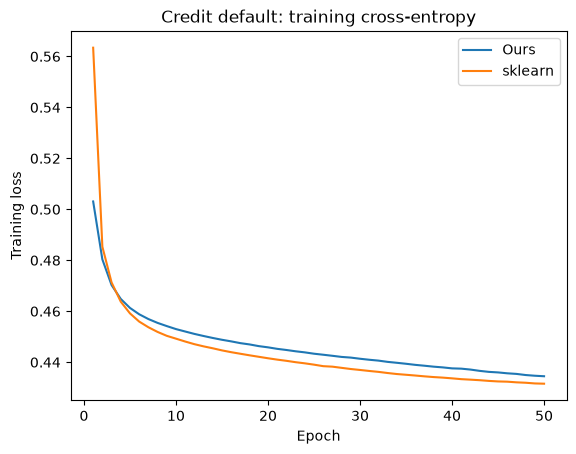

In [8]:
credit_encoded = pd.get_dummies(credit.drop(columns="ID"), columns=["SEX", "EDUCATION", "MARRIAGE"], dtype=float)
y_credit = credit_encoded.pop("default.payment.next.month").to_numpy()
X_credit = credit_encoded.to_numpy()
print("Features after encoding:", X_credit.shape[1])

X_train, X_test, y_train, y_test = split_and_scale(X_credit, y_credit, stratify=True)
config = dict(hidden_layer_size=32, activation="relu", learning_rate=0.01, batch_size=64, max_iter=50)

ours = SimpleSLPClassifier(**config, random_state=SEED).fit(X_train, y_train)
sk = sklearn_twin(MLPClassifier, config).fit(X_train, y_train)
acc_ours, acc_sk = ours.score(X_test, y_test), sk.score(X_test, y_test)
baseline = np.mean(y_test == 0)

print(f"Baseline 'always 0'  accuracy = {baseline:.3f}")
print(f"Ours                 accuracy = {acc_ours:.3f}")
print(f"sklearn              accuracy = {acc_sk:.3f}")
tn, fp, fn, tp = confusion_matrix(y_test, ours.predict(X_test)).ravel()
print(f"Ours: TN={tn} FP={fp} FN={fn} TP={tp}, share of defaults detected (recall) = {tp / (tp + fn):.3f}")

results += [("Credit default (Kaggle)", "Accuracy", "Ours", acc_ours),
            ("Credit default (Kaggle)", "Accuracy", "sklearn", acc_sk),
            ("Credit default (Kaggle)", "Accuracy", "Baseline", baseline)]
plot_losses({"Ours": ours.loss_curve_, "sklearn": sk.loss_curve_}, "Credit default: training cross-entropy")

**Reading.** Both implementations reach the same accuracy, a few points above the baseline. The confusion
matrix shows what accuracy hides: only about one default in three is detected, because the 0.5 threshold
favours the majority class. A real scoring model would lower the threshold or reweight the classes.

### 5.2 Regression: California Housing Prices (`data/housing.csv`)

Kaggle, *California Housing Prices* (camnugent): 20,640 districts from the 1990 census.
Target `median_house_value`, in dollars.

In [9]:
housing = pd.read_csv("data/housing.csv")
print("Shape:", housing.shape)
print("Missing values:", housing.isna().sum()[housing.isna().sum() > 0].to_dict())
print("ocean_proximity:", housing["ocean_proximity"].value_counts().to_dict())
print("Districts at the 500,001 $ cap:", (housing["median_house_value"] >= 500_001).sum())

Shape: (20640, 10)
Missing values: {'total_bedrooms': 207}
ocean_proximity: {'<1H OCEAN': 9136, 'INLAND': 6551, 'NEAR OCEAN': 2658, 'NEAR BAY': 2290, 'ISLAND': 5}
Districts at the 500,001 $ cap: 965


Preprocessing:
* **One-hot encode `ocean_proximity`** (text, 5 categories without order).
* Split first, then **fill the 207 missing `total_bedrooms` with the median of the training set**
  (median rather than mean: the variable is very skewed). Using all the data would leak test information.
* Standardize the features on the training set; the target is standardized as for diabetes.

Configuration: 64 hidden neurons, relu, learning rate 0.01, batch size 64, 200 epochs.

Ours     test R² = 0.750   RMSE = 57,218 $
sklearn  test R² = 0.744   RMSE = 57,940 $


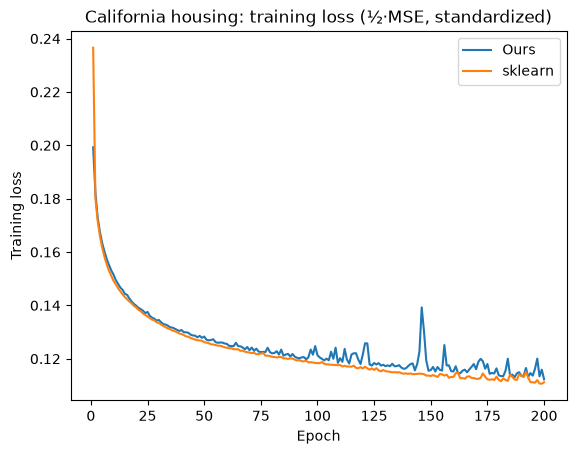

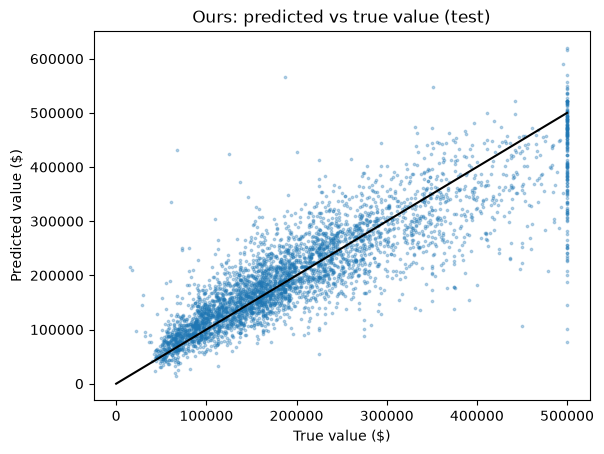

In [10]:
housing_encoded = pd.get_dummies(housing, columns=["ocean_proximity"], dtype=float)
y = housing_encoded.pop("median_house_value").to_numpy()
X_train_df, X_test_df, y_train, y_test = train_test_split(housing_encoded, y, test_size=0.2, random_state=SEED)

median = X_train_df["total_bedrooms"].median()  # computed on TRAIN only
X_train_df, X_test_df = X_train_df.fillna({"total_bedrooms": median}), X_test_df.fillna({"total_bedrooms": median})
scaler = StandardScaler().fit(X_train_df)
X_train, X_test = scaler.transform(X_train_df), scaler.transform(X_test_df)
config = dict(hidden_layer_size=64, activation="relu", learning_rate=0.01, batch_size=64, max_iter=200)

ours = SimpleSLPRegressor(**config, random_state=SEED).fit(X_train, y_train)
y_mean, y_std = y_train.mean(), y_train.std()
sk = sklearn_twin(MLPRegressor, config).fit(X_train, (y_train - y_mean) / y_std)
pred_ours, pred_sk = ours.predict(X_test), sk.predict(X_test) * y_std + y_mean

for name, pred in [("Ours", pred_ours), ("sklearn", pred_sk)]:
    rmse = np.sqrt(np.mean((y_test - pred) ** 2))
    print(f"{name:8s} test R² = {r2_score(y_test, pred):.3f}   RMSE = {rmse:,.0f} $")

results += [("California housing (Kaggle)", "R²", "Ours", ours.score(X_test, y_test)),
            ("California housing (Kaggle)", "R²", "sklearn", r2_score(y_test, pred_sk))]
plot_losses({"Ours": ours.loss_curve_, "sklearn": sk.loss_curve_}, "California housing: training loss (½·MSE, standardized)")

plt.scatter(y_test, pred_ours, s=3, alpha=0.3)
plt.plot([0, 500_001], [0, 500_001], color="black")
plt.title("Ours: predicted vs true value (test)")
plt.xlabel("True value ($)")
plt.ylabel("Predicted value ($)")
plt.show()

**Reading.** Both models explain about 75 % of the variance (error around 57,000 $) and the loss curves
follow each other (ours is a bit noisier: it is a snapshot after each epoch, scikit-learn's is an average
over the epoch). The vertical line at 500,001 $ on the scatter plot is the **cap** of the dataset: the true
price of the most expensive districts is unknown, so no model can learn it.

## 6. Early stopping

With `early_stopping=True`, `fit` holds out `validation_fraction` (10 %) of the training data and computes
the loss on it after each epoch. When it has not decreased by more than `tol` for `n_iter_no_change` (10)
epochs, training stops and the **weights of the best validation epoch are restored**.

Test: a deliberately large network (128 neurons, learning rate 0.05, 300 epochs) on the noisy credit
dataset, which makes it overfit. Three runs with the same seed:
1. no early stopping;
2. early stopping (patience 10);
3. a monitoring run that never stops (`n_iter_no_change=300`) but records the validation loss for all 300
   epochs. With the same seed it uses the same validation split as run 2.

No early stopping: 300 epochs, test accuracy = 0.798 (6.3 s)
Early stopping:    stopped at epoch 41, best epoch 31, test accuracy = 0.819 (0.8 s)


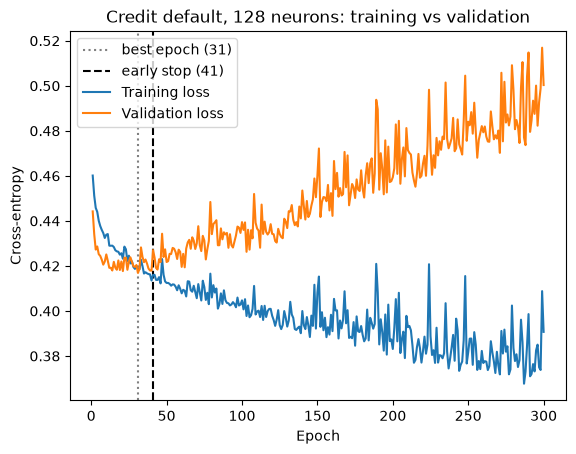

In [11]:
X_train, X_test, y_train, y_test = split_and_scale(X_credit, y_credit, stratify=True)
config = dict(hidden_layer_size=128, activation="relu", learning_rate=0.05, batch_size=64, max_iter=300,
              random_state=SEED)

start = time.perf_counter()
no_stop = SimpleSLPClassifier(**config).fit(X_train, y_train)
t_no_stop = time.perf_counter() - start
start = time.perf_counter()
early = SimpleSLPClassifier(**config, early_stopping=True).fit(X_train, y_train)
t_early = time.perf_counter() - start
monitor = SimpleSLPClassifier(**config, early_stopping=True, n_iter_no_change=300).fit(X_train, y_train)

best_epoch = int(np.argmin(early.validation_loss_curve_)) + 1
print(f"No early stopping: {no_stop.n_iter_} epochs, test accuracy = {no_stop.score(X_test, y_test):.3f} ({t_no_stop:.1f} s)")
print(f"Early stopping:    stopped at epoch {early.n_iter_}, best epoch {best_epoch}, "
      f"test accuracy = {early.score(X_test, y_test):.3f} ({t_early:.1f} s)")

plt.axvline(best_epoch, color="gray", linestyle=":", label=f"best epoch ({best_epoch})")
plt.axvline(early.n_iter_, color="black", linestyle="--", label=f"early stop ({early.n_iter_})")
plot_losses({"Training loss": monitor.loss_curve_, "Validation loss": monitor.validation_loss_curve_},
            "Credit default, 128 neurons: training vs validation", ylabel="Cross-entropy")

**Reading.** The training loss keeps decreasing, but the validation loss reaches a minimum early and then
rises: the network starts memorising noise (**overfitting**). Early stopping stops 10 epochs after the
minimum, restores the best weights, and gets a **better test accuracy than the 300-epoch model, much faster**.

## 7. Effect of the batch size

Same model on breast cancer (455 training samples), same learning rate (0.01) and 100 epochs; only the batch
size changes: **full batch** (455, 1 update per epoch), mini-batches of 128 and 32, and batch size 1
(pure stochastic gradient descent, 455 updates per epoch).

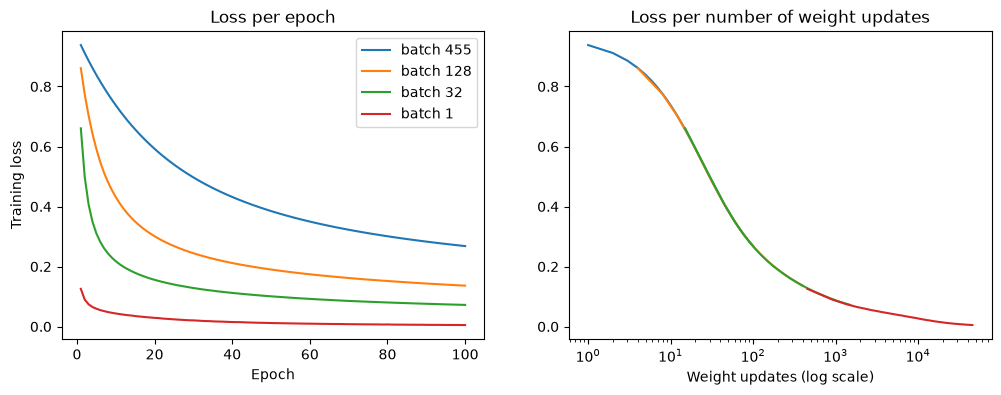

   Batch size  Updates / epoch  Final train loss  Test accuracy  Time (s)
0         455                1            0.2682         0.9474    0.0112
1         128                4            0.1363         0.9474    0.0162
2          32               15            0.0721         0.9649    0.0354
3           1              455            0.0050         0.9561    0.5429


In [12]:
X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = split_and_scale(X, y, stratify=True)
n_train = len(X_train)

rows, curves = [], {}
for batch_size in [n_train, 128, 32, 1]:
    start = time.perf_counter()
    model = SimpleSLPClassifier(hidden_layer_size=32, activation="relu", learning_rate=0.01,
                                batch_size=batch_size, max_iter=100, random_state=SEED).fit(X_train, y_train)
    seconds = time.perf_counter() - start
    updates_per_epoch = int(np.ceil(n_train / batch_size))
    rows.append((batch_size, updates_per_epoch, model.loss_curve_[-1], model.score(X_test, y_test), seconds))
    curves[f"batch {batch_size}"] = (updates_per_epoch, model.loss_curve_)

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4))
for label, (updates_per_epoch, losses) in curves.items():
    left.plot(range(1, 101), losses, label=label)
    right.plot(updates_per_epoch * np.arange(1, 101), losses, label=label)
left.set(title="Loss per epoch", xlabel="Epoch", ylabel="Training loss")
right.set(title="Loss per number of weight updates", xlabel="Weight updates (log scale)", xscale="log")
left.legend()
plt.show()

print(pd.DataFrame(rows, columns=["Batch size", "Updates / epoch", "Final train loss", "Test accuracy", "Time (s)"]).round(4))

**Reading.**
* **Per epoch**, smaller batches go down much faster because they make many more updates per pass over the
  data. After 100 epochs, full batch has made only 100 small steps and is far from converged.
* **Per update**, the curves lie on top of each other: a gradient on 32 samples (or even 1) is a noisy but
  unbiased estimate of the full gradient, and with this small learning rate the noise does not matter.
  What differs is the cost of one update.
* Batch size 1 reaches the lowest loss but is the slowest: tens of thousands of tiny updates cannot use
  NumPy's vectorization. Mini-batches (32–128) are the usual compromise.

## 8. Summary

In [13]:
summary = pd.DataFrame(results, columns=["Dataset", "Metric", "Model", "Test score"]).pivot_table(
    index=["Dataset", "Metric"], columns="Model", values="Test score", sort=False)[["Ours", "sklearn", "Baseline"]]
summary["Ours - sklearn"] = summary["Ours"] - summary["sklearn"]
print(summary.round(3))

Model                                  Ours  sklearn  Baseline  Ours - sklearn
Dataset                     Metric                                            
Diabetes                    R²        0.503    0.484       NaN           0.019
Breast cancer               Accuracy  0.965    0.965     0.632           0.000
Credit default (Kaggle)     Accuracy  0.815    0.815     0.779           0.001
California housing (Kaggle) R²        0.750    0.744       NaN           0.006


### Conclusion

* On the four datasets, our NumPy implementation reaches **the same test score as scikit-learn** with the
  same configuration, and the loss curves almost overlap. With the gradient check, this validates the
  forward pass, the backpropagation and the gradient descent updates.
* **Standardization is decisive**, for the inputs and for the regression target (plain SGD diverges on the
  raw diabetes target).
* **Mini-batches** give the best trade-off between updates per epoch and vectorized computation.
  **Early stopping** saves computation and, on a model that overfits, improves the test score.

### Limitations

* One hidden layer and plain SGD (no momentum or Adam): convergence needs many epochs.
* No regularization other than early stopping (no L2 penalty, no dropout).
* Hyper-parameters chosen by hand, and each score comes from a single 80/20 split: differences of 1–2
  points between models are within noise.
* On the imbalanced credit dataset, accuracy is a weak metric; recall, AUC or a tuned threshold would be
  needed. The decision threshold is fixed at 0.5.
* The housing target is capped at 500,001 $, which limits what any model can learn on expensive districts.